# Day 2 · 05 — Lab: hierarchy and coherence (20 min)

The store plans at several levels: total → department → class → subclass → item. Forecasts made
independently at each level do **not add up**. Reconciliation makes them coherent; the question is which
method, and what it costs or gains at each level.

| Method | Idea |
|---|---|
| `BottomUp` | forecast items, sum upwards |
| `TopDown` (forecast proportions) | forecast the total, split it down |
| `MiddleOut` (class) | forecast a middle level, sum up and split down |
| `MinTrace` `ols` / `wls_struct` / `wls_var` | least-squares adjustment of all levels at once, weighted by (estimated) error covariance |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

/home/user/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Intuition: the numbers must add up

![Incoherent forecasts](slides/img/hierarchy_tree.png)

Forecast every level separately and the items will not add up to the department, like a budget whose line
items disagree with its total. Reconciliation decides **whom to believe**:

* **BottomUp** trusts the items and sums them.
* **TopDown** trusts the total and splits it by historical proportions.
* **MinTrace** trusts each level in proportion to how reliable it has been, and moves every number as little as
  possible to make them add up.

## 1. Build the hierarchy

`hierarchy.csv` maps subclass → class → department. Items without a subclass (448 in the full data) cannot
be placed and are dropped from this lab.

In [2]:
from hierarchicalforecast.utils import aggregate

panel = bc.load_panel().filter(pl.col("subclass_id") > 0)
hier = pl.read_csv(bc.DATA_DIR / "hierarchy.csv")

df = panel.select(
    pl.lit("Total").alias("total"),
    pl.format("D{}", pl.col("department_id")).alias("department"),
    pl.format("C{}", pl.col("class_id")).alias("class"),
    pl.format("S{}", pl.col("subclass_id")).alias("subclass"),
    pl.col("unique_id").alias("item"),
    "ds", "y",
).to_pandas()
df["ds"] = pd.to_datetime(df["ds"])

spec = [
    ["total"],
    ["total", "department"],
    ["total", "department", "class"],
    ["total", "department", "class", "subclass"],
    ["total", "department", "class", "subclass", "item"],
]
Y_df, S_df, tags = aggregate(df, spec, sparse_s=True)   # sparse S: ~19,000 nodes would not fit densely in memory
print({k.split("/")[-1]: len(v) for k, v in tags.items()})

test_start = pd.Timestamp(bc.TEST_START)
Y_train = Y_df[Y_df.ds < test_start]
Y_test = Y_df[Y_df.ds >= test_start]

{'total': 1, 'department': 148, 'class': 502, 'subclass': 1467, 'item': 17216}


## 2. Base forecasts at every level

AutoETS for every node (fast, decent at aggregate levels), with in-sample fitted values, which `MinTrace`
needs to estimate the error covariance.

In [3]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, Naive

sf = StatsForecast(models=[AutoETS(season_length=1)], freq=bc.FREQ, n_jobs=-1, fallback_model=Naive())
with bc.Timer() as t_base:
    Y_hat = sf.forecast(df=Y_train, h=bc.H, fitted=True)
Y_fitted = sf.forecast_fitted_values()
print(f"{Y_hat.unique_id.nunique():,} nodes forecast in {t_base.seconds:.0f}s")

19,334 nodes forecast in 20s


## 3. Reconcile

In [4]:
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.methods import BottomUpSparse, MiddleOutSparse, MinTraceSparse, TopDownSparse

# Sparse versions: with every eligible item the hierarchy has about 19,000 nodes, and the dense S matrix and
# MinT projection would need well over the 15 GB of a laptop. MinT with a full shrunk covariance (`mint_shrink`)
# needs a dense 19,000 x 19,000 covariance, so on the full data the weighted MinT is `wls_var`: each node weighted
# by its own in-sample error variance. The library's sparse `wls_var` stalls on this hierarchy (node variances
# span 13 orders of magnitude), so `bc.mint_wls_var` solves the same estimator with a preconditioned solver; it
# matches the library's dense `wls_var` to 1e-8 on a small hierarchy.
reconcilers = [
    BottomUpSparse(),
    TopDownSparse(method="forecast_proportions"),
    MiddleOutSparse(middle_level="total/department/class", top_down_method="forecast_proportions"),
    MinTraceSparse(method="ols"),
    MinTraceSparse(method="wls_struct"),
]
hrec = HierarchicalReconciliation(reconcilers=reconcilers)
with bc.Timer() as t_rec:
    Y_rec = hrec.reconcile(Y_hat_df=Y_hat, Y_df=Y_fitted, S_df=S_df, tags=tags)
    Y_rec = Y_rec.merge(bc.mint_wls_var(Y_hat, Y_fitted, S_df).rename(columns={"MinT-wls_var": "AutoETS/MinT-wls_var"}),
                        on=["unique_id", "ds"])
print(f"reconciled in {t_rec.seconds:.1f}s")
methods = [c for c in Y_rec.columns if c.startswith("AutoETS")]
SHORT = {"AutoETS": "Base (incoherent)", "AutoETS/BottomUpSparse": "BottomUp",
         "AutoETS/TopDownSparse_method-forecast_proportions": "TopDown",
         "AutoETS/MiddleOutSparse_middle_level-total/department/class_top_down_method-forecast_proportions": "MiddleOut(class)",
         "AutoETS/MinTraceSparse_method-ols": "MinT-ols", "AutoETS/MinTraceSparse_method-wls_struct": "MinT-wls_struct",
         "AutoETS/MinT-wls_var": "MinT-wls_var"}
Y_rec = Y_rec.rename(columns=SHORT)
methods = [SHORT.get(c, c) for c in methods]
methods

reconciled in 15.2s


['Base (incoherent)',
 'BottomUp',
 'TopDown',
 'MiddleOut(class)',
 'MinT-ols',
 'MinT-wls_struct',
 'MinT-wls_var']

### Coherence check: do the items sum to the total?

In [5]:
items = tags["total/department/class/subclass/item"]
chk = {}
for m in methods:
    tot = Y_rec[Y_rec.unique_id == "Total"].set_index("ds")[m]
    bottom = Y_rec[Y_rec.unique_id.isin(items)].groupby("ds")[m].sum()
    chk[m] = float((tot - bottom).abs().max())
pd.Series(chk, name="max |total − Σ items|").round(2)

Base (incoherent)    3662809.84
BottomUp                   0.00
TopDown                    0.00
MiddleOut(class)           0.00
MinT-ols                   0.00
MinT-wls_struct            0.00
MinT-wls_var               0.00
Name: max |total − Σ items|, dtype: float64

Every reconciled column should show 0 (up to rounding); only the base forecasts are allowed to disagree.
**Always run this check.** With `hierarchicalforecast` 1.5.3, `MiddleOut` fails it on this hierarchy: the
total and departments agree, but the classes and everything below them do not add up to the departments.
A "reconciled" forecast that does not add up is not reconciled, so any method that fails is dropped from the
comparison below.

In [6]:
total_size = Y_train[Y_train.unique_id == "Total"].y.mean()
incoherent = [m for m, v in chk.items() if m != "Base (incoherent)" and v > 1e-6 * total_size]
print("fails the coherence check, dropped:", incoherent)
methods = [m for m in methods if m not in incoherent]

fails the coherence check, dropped: []


## 4. Accuracy per level

Scaled errors (RMSSE against a 1-step naive, because aggregates have <2 years of history) so levels are
comparable. The question is not "which method wins" but **"where does each method pay"**.

In [7]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmsse

ev = evaluate(Y_rec.merge(Y_test, on=["unique_id", "ds"]), metrics=[partial(rmsse, seasonality=1)],
              models=methods, train_df=Y_train)
ev["metric"] = "rmsse"
level_of = {uid: lvl.split("/")[-1] for lvl, uids in tags.items() for uid in uids}
ev["level"] = ev.unique_id.map(level_of)
by_level = ev.groupby("level")[methods].mean().loc[["total", "department", "class", "subclass", "item"]]
by_level.round(3)

,Base (incoherent),BottomUp,TopDown,MiddleOut(class),MinT-ols,MinT-wls_struct,MinT-wls_var
level,,,,,,,
total,0.891,1.208,0.891,1.009,0.892,1.011,1.071
department,1.337,1.347,1.317,1.312,19.222,1.335,1.312
class,1.278,1.288,1.277,1.278,30.280,1.777,1.260
subclass,1.297,1.295,1.303,1.308,16.823,1.671,1.274
item,2.069,2.069,2.117,2.124,8.873,4.781,2.068


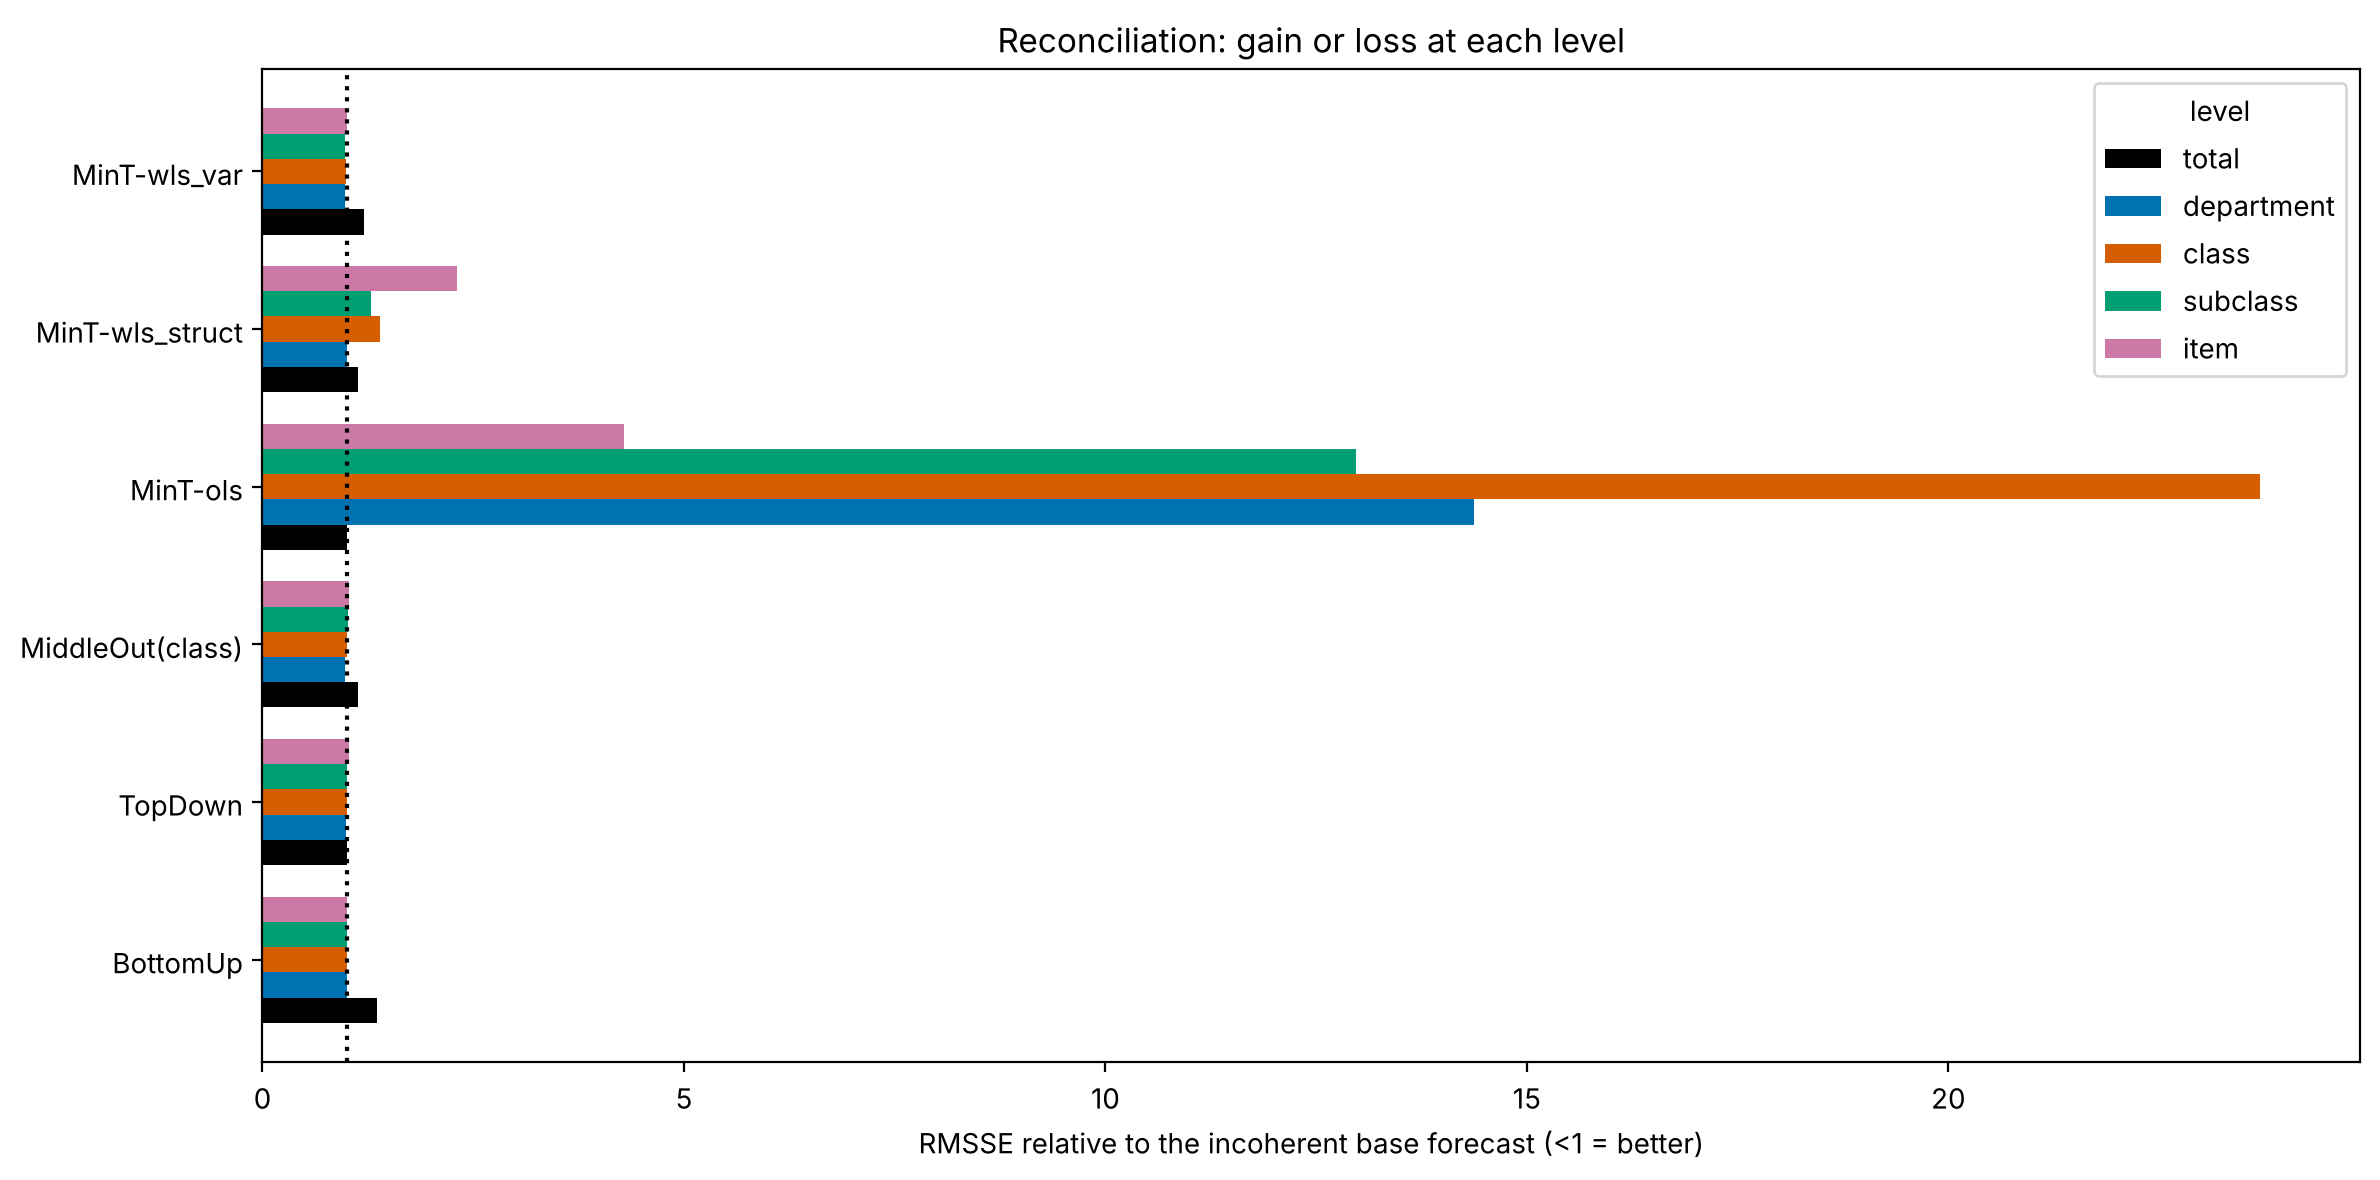

In [8]:
rel = by_level.div(by_level["Base (incoherent)"], axis=0)
ax = rel.drop(columns="Base (incoherent)").T.plot.barh(figsize=(12, 6), width=0.8)
ax.axvline(1, color="black", ls=":")
ax.set_xlabel("RMSSE relative to the incoherent base forecast (<1 = better)")
ax.set_title("Reconciliation: gain or loss at each level")
plt.tight_layout()

### Reading the result

![Lab 05 results](slides/img/res_lab05.png)

In the reference run (ratios to the incoherent base forecasts). Scores in this table are scaled by the
1-step naive error, so they are not on the leaderboard scale; read the ratios.

* **BottomUp**: items unchanged, total ≈ 36 % worse. Small item biases add up across 17,000 items.
* **TopDown**: total unchanged, items ≈ 2 % worse. Fixed proportions miss item-level promotions.
* **MiddleOut** (from the class level) sits in between: total ≈ 13 % worse, items ≈ 3 % worse.
* **MinT-wls_var**: about 2 % *better* than the base at the department, class and subclass levels, level with
  it at the items (1.400 vs 1.402 on the leaderboard metric), and coherent: coherence comes for free there. The
  price is paid at the top, ≈ 20 % worse on the store total, because the total is one node among 19,000.
* **MinT-ols** is 4–24× worse below the total, and `wls_struct` up to 2.3× worse at the items. Both ignore
  how noisy each node really is: `ols` treats a 600-unit item and a department selling millions as equally
  reliable, `wls_struct` only counts how many items sit under a node. The weights are the whole point.
* `mint_shrink` (wls_var plus correlations) needs a dense 19,000 × 19,000 covariance and does not fit in a
  laptop's memory at this size; that is why this lab uses the sparse reconcilers.

*Reference run: all 17,241 eligible series, 4-core laptop CPU. Your numbers will differ a little; the reading
should not.*

## 5. Item level onto the leaderboard

The item level is the leaderboard level, so the reconciled item forecasts can be compared with every other
model today. Add the best method.

In [9]:
train_pl, test_pl = bc.split(panel)
item_fc = Y_rec[Y_rec.unique_id.isin(items)][["unique_id", "ds"] + methods].copy()
item_fc["unique_id"] = item_fc["unique_id"].str.split("/").str[-1]    # "Total/D…/C…/S…/123_S1" → "123_S1"
# Base and BottomUp item forecasts are the same AutoETS as notebook 00 (on the 17,216 items that fit the
# hierarchy), so only the methods that change the item level go on the leaderboard.
item_fc = item_fc.rename(columns={"TopDown": "ETS_TopDown", "MinT-wls_struct": "ETS_MinT-wls",
                                  "MinT-wls_var": "ETS_MinT-wls_var"})
keep = ["unique_id", "ds", "ETS_TopDown", "ETS_MinT-wls", "ETS_MinT-wls_var"]
bc.save_forecasts(item_fc[keep], "05_hierarchy", actuals=test_pl)
# every node of the hierarchy (total → items), every method, with actuals: for any metric at any level
bc.save_raw(Y_rec.merge(Y_test[["unique_id", "ds", "y"]], on=["unique_id", "ds"], how="left"), "05_hierarchy_all_levels", "test")
bc.record(item_fc[keep], test_pl, train_pl, lab="05 hierarchy",
          fit_seconds=t_base.seconds + t_rec.seconds)

,model,mean_rmsse,median_rmsse,mean_mase,median_mase,mean_smape,n_series,wape,bias_pct,lab,fit_seconds,notes,recorded_at
0,ETS_MinT-wls_var,1.400424,0.692147,3.663077,0.761853,0.295727,17213,0.397162,0.046570,05 hierarchy,34.941639,,2026-11-21 23:42:48
1,ETS_TopDown,1.422992,0.698255,3.665797,0.760143,0.301555,17213,0.401567,0.022269,05 hierarchy,34.941639,,2026-11-21 23:42:48
2,ETS_MinT-wls,2.034115,0.761255,5.551883,0.824193,0.334260,17213,0.407089,0.045420,05 hierarchy,34.941639,,2026-11-21 23:42:48


In [10]:
# Like for like at the item level: base vs reconciled, same series, leaderboard metric (52-week scale)
item_cmp = item_fc.rename(columns={"Base (incoherent)": "ETS_base"})
bc.summarise(bc.score(item_cmp, test_pl, train_pl, ["ETS_base", "BottomUp"] + keep[2:]), item_cmp, test_pl)

,model,mean_rmsse,median_rmsse,mean_mase,median_mase,mean_smape,n_series,wape,bias_pct
0,ETS_MinT-wls_var,1.400424,0.692147,3.663077,0.761853,0.295727,17213,0.397162,0.046570
1,ETS_base,1.402403,0.693836,3.666909,0.764733,0.299613,17213,0.402218,0.059959
2,BottomUp,1.402403,0.693836,3.666909,0.764733,0.299613,17213,0.402218,0.059959
3,ETS_TopDown,1.422992,0.698255,3.665797,0.760143,0.301555,17213,0.401567,0.022269
4,ETS_MinT-wls,2.034115,0.761255,5.551883,0.824193,0.334260,17213,0.407089,0.045420


## Discussion

* BottomUp is free at the item level and usually poor at the top. TopDown is the reverse. Who consumes which
  level in the business?
* `wls_var` uses each node's own error variance but ignores correlations between nodes. `mint_shrink` adds them,
  but needs a 19,000 × 19,000 covariance estimated from ~90 weeks of residuals. Try it on one department: does
  it beat `wls_var` there, and is the gain worth the memory?
* Swap the base model for a global model (e.g. LightGBM from Day 1) at the item level and keep ETS above.
  Reconciliation does not care where base forecasts come from.